<a href="https://colab.research.google.com/github/seanyi-creator/ba-305-project/blob/main/03_tree_decision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workstream 2 — Decision tree and random forest
**Question:** When a building permit is filed in San Francisco, can its project details (type, cost, unit and story changes, location, …) predict whether the project will be abandoned rather than completed?

**Who acts on it:** SF's Department of Building Inspection and Planning could flag high-risk permits at filing, prioritise them, and point applicants to extensions or fee deferrals, so fewer planned homes are left unfinished.

This notebook is method 2 of 2 (logistic regression is in `02_logistic.ipynb`). It covers:

| Step | What it does |
|---|---|
| 1 | How a tree chooses a split: **misclassification error, Gini and entropy**, by hand and on our data |
| 2 | A fully grown tree, to show what overfitting looks like |
| 3 | Depth vs. accuracy for Gini and entropy (underfitting → overfitting) |
| 4 | **Hyperparameter tuning** of the tree with grouped 5-fold cross-validation |
| 5 | A small tree drawn out, to read the rules |
| 6 | **Random forest**: why it helps, and tuning it |
| 7 | **Test-set results** for every model next to the baselines and logistic regression |
| 8 | Choosing the flagging cutoff from the cost of each mistake |
| 9 | What drives the forest (permutation importance) |
| 10 | **Comparison and conclusions** |

⏱ **Runtime:** about 10 minutes on an 8-core laptop, longer on free Colab (most of it in Steps 3, 4 and 6). Run it once and keep the outputs.

> **Note on the label.** The proposal writes the target as *Complete = 1*. All three notebooks code it the other way round: **`y = 1` means the permit did *not* finish** (expired, cancelled, withdrawn, disapproved, revoked or denied). The city acts on the risky permits, so "positive" should mean "at risk"; then *recall* = share of failing permits we catch and *precision* = share of flagged permits that really fail. Flipping the label changes nothing about AUC or accuracy.

In [1]:
# --- setup ---
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, cross_validate, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)
pd.set_option('display.max_columns', 50)

## Shared data (copied unchanged from `02_logistic.ipynb`)
Same rows, same features, same grouped train/test split and the same preprocessor as logistic regression, so the models are compared on identical permits.

In [2]:
# --- Sean: SHARED CELL — load, target, filing-year filter, leakage drops, features, split, preprocessor ---
# Copy this whole cell into your notebook, then run:
#   X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data()
# and cross-validate with cv=make_cv() and .fit(X_train, y_train, groups=groups_train)
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PERMITS_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-07-05/sf_permits.csv"

# Statuses where the outcome is final. 'complete' = 0; every other final status = 1 (did not finish).
FINAL_STATUS = {'complete': 0, 'expired': 1, 'cancelled': 1, 'withdrawn': 1,
                'disapproved': 1, 'revoked': 1, 'denied': 1}
YEAR_MIN, YEAR_MAX = 2000, 2013   # filing years kept (see Step 2)
RANDOM_STATE = 42                 # everyone uses this, so the split is identical

# Columns recorded AFTER filing (leak the outcome) or that are only labels for a case (see Step 3).
LEAKAGE_COLS = ['status', 'status_date', 'completed_date', 'issued_date', 'permit_expiration_date',
                'first_construction_document_date', 'revised_cost']
ID_COLS = ['permit_number', 'record_id', 'block', 'lot', 'street_number', 'street_number_suffix',
           'street_name', 'street_suffix', 'unit', 'unit_suffix', 'location', 'description',
           'permit_creation_date', 'filed_date', 'date', 'zipcode', 'tidf_compliance',
           'permit_type', 'existing_construction_type', 'proposed_construction_type']
# description: free text, left out of the baseline feature set (an optional extension).
# zipcode: overlaps with neighborhood; permit_type / construction_type codes: duplicates of their text labels.
# tidf_compliance: 100% missing.

NUMERIC = ['log_estimated_cost', 'cost_is_placeholder', 'plansets',
           'existing_units', 'proposed_units', 'unit_change',
           'number_of_existing_stories', 'number_of_proposed_stories', 'story_change',
           'filing_year', 'filing_month']
CATEGORICAL = ['permit_type_definition', 'existing_use', 'proposed_use', 'use_changes',
               'existing_construction_type_description', 'proposed_construction_type_description',
               'structural_notification', 'site_permit', 'fire_only_permit',
               'voluntary_soft_story_retrofit', 'neighborhoods_analysis_boundaries',
               'supervisor_district']


def load_permits(url=PERMITS_URL):
    """Raw file, as downloaded."""
    return pd.read_csv(url, low_memory=False)


def resolved_permits(raw):
    """Keep permits with a final outcome, filed in YEAR_MIN..YEAR_MAX, and add the target y."""
    df = raw[raw['status'].isin(FINAL_STATUS)].copy()
    df['filed'] = pd.to_datetime(df['filed_date'])
    df = df[df['filed'].dt.year.between(YEAR_MIN, YEAR_MAX)]
    df['y'] = df['status'].map(FINAL_STATUS)          # 1 = did not finish
    return df


def add_features(df):
    """Features that are all known on the day the permit is filed."""
    out = df.copy()
    cost = out['estimated_cost']
    out['cost_is_placeholder'] = (cost <= 1).astype(int)          # $0/$1 entered as a placeholder
    out['log_estimated_cost'] = np.log10(cost.where(cost > 1))     # skewed: $1 to $500M+, so use log10
    out['unit_change'] = out['proposed_units'] - out['existing_units']
    out['story_change'] = out['number_of_proposed_stories'] - out['number_of_existing_stories']
    both_known = out['existing_use'].notna() & out['proposed_use'].notna()
    out['use_changes'] = (out['existing_use'] != out['proposed_use']).map({True: 'yes', False: 'no'}).where(both_known)
    out['filing_year'] = out['filed'].dt.year
    out['filing_month'] = out['filed'].dt.month
    out['supervisor_district'] = out['supervisor_district'].astype('Int64').astype(str).replace('<NA>', np.nan)
    for c in ['structural_notification', 'site_permit', 'fire_only_permit', 'voluntary_soft_story_retrofit']:
        out[c] = out[c].fillna('N')                                # blank means "not flagged"
    return out


def make_preprocessor():
    """Fit inside a Pipeline, so imputation and scaling learn from training folds only."""
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),  # median + a 'was missing' flag
        ('scale', StandardScaler()),
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50)),  # rare levels pooled
    ])
    return ColumnTransformer([('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)])


def batch_id(df):
    """Permits filed for the same lot on the same day are one project's batch (see Step 5)."""
    return df['block'].astype(str) + '-' + df['lot'].astype(str) + '-' + df['filed_date'].astype(str)


def make_cv():
    """5-fold CV that keeps each batch inside one fold and keeps the class mix similar."""
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def get_permit_data(raw=None, test_size=0.2):
    """One call for teammates: same rows, features, grouped split and preprocessor for everyone."""
    raw = load_permits() if raw is None else raw
    df = add_features(resolved_permits(raw)).reset_index(drop=True)
    X, y, groups = df[NUMERIC + CATEGORICAL], df['y'], batch_id(df)
    train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=test_size,
                                                 random_state=RANDOM_STATE).split(X, y, groups))
    return (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx],
            groups.iloc[train_idx], make_preprocessor())

In [3]:
# --- load the shared split ---
X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data()
print(f'Train: {len(X_train):,} permits · Test: {len(X_test):,} permits')
print(f'Did not finish: {y_train.mean():.1%} of train, {y_test.mean():.1%} of test')

Train: 49,676 permits · Test: 12,472 permits
Did not finish: 35.7% of train, 36.7% of test


## Step 1 — How a tree chooses a split: error, Gini and entropy
A decision tree asks yes/no questions ("is the permit an *otc alterations* permit?", "is log10(cost) ≤ 4.2?"). At each node it tries every possible question and keeps the one that makes the two child groups **purest**: each child as close as possible to all-"completed" or all-"did not finish".

"Purity" needs a number. With *p* = share of permits in a node that did not finish, the three classic **impurity** measures are:

| Measure | Formula | 0 when | Largest when |
|---|---|---|---|
| Misclassification error | 1 − max(p, 1 − p) | node is pure | p = 0.5 (0.5) |
| Gini index | 1 − p² − (1 − p)² = 2p(1 − p) | node is pure | p = 0.5 (0.5) |
| Entropy | −p log₂p − (1 − p) log₂(1 − p) | node is pure | p = 0.5 (1.0) |

A split is scored by its **impurity decrease**: impurity of the parent minus the size-weighted impurity of the two children. The tree takes the split with the largest decrease. (With entropy, this decrease is called *information gain*.)

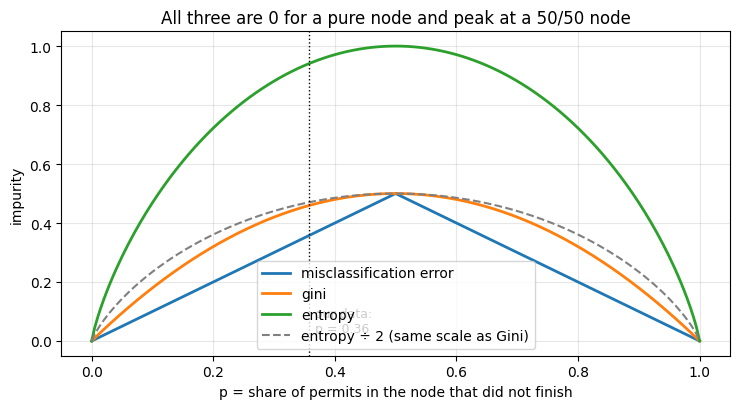

In [4]:
# --- Step 1 — the three impurity measures ---
def misclassification_error(p):
    return 1 - np.maximum(p, 1 - p)

def gini(p):
    return 2 * p * (1 - p)

def entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)          # avoid log(0)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

IMPURITY = {'misclassification error': misclassification_error, 'gini': gini, 'entropy': entropy}

p = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, f in IMPURITY.items():
    ax.plot(p, f(p), label=name, lw=2)
ax.plot(p, entropy(p) / 2, ls='--', color='grey', label='entropy ÷ 2 (same scale as Gini)')
ax.axvline(y_train.mean(), color='black', ls=':', lw=1)
ax.text(y_train.mean() + 0.01, 0.03, f'our data:\np = {y_train.mean():.2f}', fontsize=9)
ax.set_xlabel('p = share of permits in the node that did not finish'); ax.set_ylabel('impurity')
ax.set_title('All three are 0 for a pure node and peak at a 50/50 node')
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

**Reading the curves:** Gini and entropy (once halved) are almost the same shape: smooth and curved. Misclassification error is a **straight-line "tent"**. That shape difference is the whole story of the next cell.

### Why trees use Gini or entropy rather than error to grow
A textbook example: a node of 800 permits, 400 failed and 400 completed. Two candidate splits:
- **Split A:** (300 failed, 100 completed) and (100 failed, 300 completed): both children are 75/25.
- **Split B:** (200 failed, 400 completed) and (200 failed, 0 completed): the second child is perfectly pure.

In [5]:
# --- Step 1 — score two candidate splits under each measure ---
def split_report(children):
    """children: list of (n_failed, n_completed) for each child node. Parent = their sum."""
    fail = sum(c[0] for c in children); n = sum(c[0] + c[1] for c in children)
    rows = {}
    for name, f in IMPURITY.items():
        before = f(fail / n)
        after = sum((a + b) / n * f(a / (a + b)) for a, b in children)
        rows[name] = {'parent impurity': before, 'children (weighted)': after, 'decrease': before - after}
    return pd.DataFrame(rows).T.round(4)

split_a = split_report([(300, 100), (100, 300)])
split_b = split_report([(200, 400), (200, 0)])
pd.concat({'Split A (75/25 + 25/75)': split_a['decrease'],
           'Split B (33/67 + pure)': split_b['decrease']}, axis=1)

,Split A (75/25 + 25/75),Split B (33/67 + pure)
misclassification error,0.2500,0.2500
gini,0.1250,0.1667
entropy,0.1887,0.3113


**Reading the table:** misclassification error scores both splits the **same** (0.25): either way, 200 of 800 permits end up on the wrong side of a majority vote. Gini and entropy both prefer **Split B**, because it creates a pure node that needs no further splitting. Because they are curved, any move toward purity gets rewarded, not just moves that flip a node's majority class.

That is why scikit-learn offers only `gini` and `entropy` (`log_loss`) as split criteria. Misclassification error is still useful, but as a measure of how good a finished model is (error rate = 1 − accuracy, reported in Step 7), not as a way to grow it.

### The same comparison on the real permits
Below, a one-split tree (a "stump") is grown on the training data with Gini and with entropy. For each chosen split we compute all three impurity decreases.

In [6]:
# --- Step 1 — the first split each criterion picks on our data ---
prep_fit = make_preprocessor().fit(X_train)
Xt = prep_fit.transform(X_train)
feat_names = [n.replace('num__', '').replace('cat__', '') for n in prep_fit.get_feature_names_out()]
y_arr = y_train.to_numpy()
scaler = prep_fit.named_transformers_['num'].named_steps['scale']

def describe(f, thr):
    """Put the split in plain words (numeric thresholds are converted back from standardized units)."""
    name = feat_names[f]
    if f < len(NUMERIC):
        return f'{name} ≤ {thr * scaler.scale_[f] + scaler.mean_[f]:.2f}'
    return f'{name}: left = no, right = yes'          # a 0/1 column

rows, root_reports = [], {}
for crit in ['gini', 'entropy']:
    stump = DecisionTreeClassifier(max_depth=1, criterion=crit, random_state=RANDOM_STATE).fit(Xt, y_arr)
    f, thr = stump.tree_.feature[0], stump.tree_.threshold[0]
    left = Xt[:, f].toarray().ravel() <= thr
    children = [(int(y_arr[side].sum()), int((1 - y_arr[side]).sum())) for side in (left, ~left)]
    rep = split_report(children)
    rows.append({'criterion': crit, 'split chosen': describe(f, thr),
                 'left: n / % did not finish': f'{left.sum():,} / {y_arr[left].mean():.1%}',
                 'right: n / % did not finish': f'{(~left).sum():,} / {y_arr[~left].mean():.1%}',
                 **{f'decrease in {k}': v for k, v in rep['decrease'].items()}})
pd.DataFrame(rows).set_index('criterion').T

criterion,gini,entropy
split chosen,filing_year ≤ 2002.50,filing_year ≤ 2002.50
left: n / % did not finish,"19,769 / 43.1%","19,769 / 43.1%"
right: n / % did not finish,"29,907 / 30.9%","29,907 / 30.9%"
decrease in misclassification error,0.0,0.0
decrease in gini,0.0072,0.0072
decrease in entropy,0.0112,0.0112


**Reading the result:** Gini and entropy pick the **same first question**: *was the permit filed in 2002 or earlier?* Older permits failed 43.1% of the time, newer ones (2003–2013) 30.9%.

The **misclassification error decrease is exactly 0**. Both children are still majority "completed", so a majority vote labels every permit "completed" before the split and after it, and error sees no improvement at all. Gini and entropy do register that the two groups now differ in risk. This is the toy example above happening on real data. A tree grown on misclassification error could not even make its first split here, which is exactly why it isn't used as a split criterion.

The very first split being the *filing year* echoes the drift found in `01_permits_prep` (failure rates fell over time). Step 9 checks how much the models lean on it.

## Step 2 — A fully grown tree overfits
With no limits, a tree keeps splitting until every leaf is pure, so it can memorise the training permits. Below, an unrestricted tree is scored on the training folds and on the held-out cross-validation folds (grouped, so a project's batch of permits never sits on both sides).

In [7]:
# --- Step 2 — unrestricted tree: training vs cross-validated scores ---
def tree_pipe(**kw):
    return Pipeline([('prep', make_preprocessor()),
                     ('model', DecisionTreeClassifier(random_state=RANDOM_STATE, **kw))])

cv = make_cv()
full = cross_validate(tree_pipe(), X_train, y_train, groups=groups_train, cv=cv,
                      scoring=['roc_auc', 'accuracy'], return_train_score=True, n_jobs=-1)
full_fit = tree_pipe().fit(X_train, y_train).named_steps['model']
print(f'Fully grown tree: depth {full_fit.get_depth()}, {full_fit.get_n_leaves():,} leaves '
      f'for {len(X_train):,} training permits')
pd.DataFrame({
    'training folds': [full['train_roc_auc'].mean(), full['train_accuracy'].mean(), 1 - full['train_accuracy'].mean()],
    'cross-validation folds': [full['test_roc_auc'].mean(), full['test_accuracy'].mean(), 1 - full['test_accuracy'].mean()],
}, index=['ROC AUC', 'accuracy', 'error rate']).round(3)

Fully grown tree: depth 66, 12,900 leaves for 49,676 training permits


,training folds,cross-validation folds
ROC AUC,1.000,0.585
accuracy,0.996,0.617
error rate,0.004,0.383


**Reading the result:** with no limits the tree grows **66 levels deep with 12,900 leaves**, about one leaf for every 4 training permits. On the permits it trained on it is essentially perfect (AUC 1.000, error 0.4%). On permits it has not seen, AUC falls to **0.585** and the error rate is **38.3%**, *worse* than just answering "completed" for everyone (≈ 36% error). It memorised noise instead of learning patterns: textbook **overfitting**. The next two steps restrict the tree to fix this.

## Step 3 — How deep should the tree be? (Gini vs. entropy)
`max_depth` is the main control on complexity. Too shallow, and the tree **underfits**: too few questions to separate risky from safe permits, so training and CV scores are both low. Too deep, and it **overfits**: training AUC keeps rising while CV AUC falls. The sweet spot is where CV AUC peaks. Both criteria are shown.

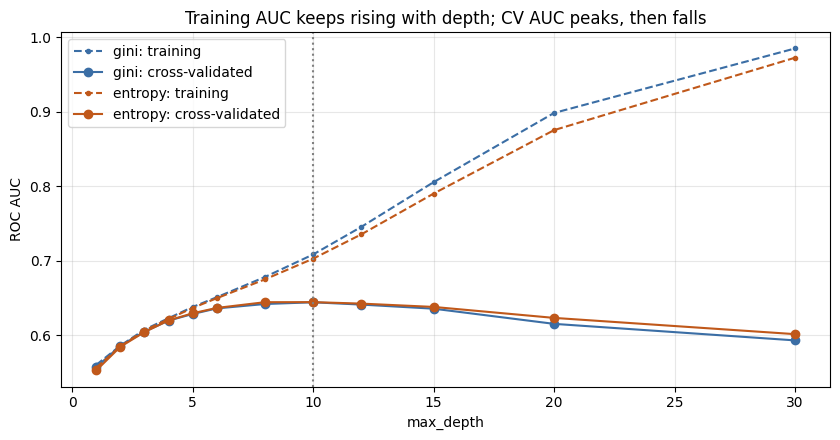

criterion,entropy,gini
max_depth,,
1,0.5531,0.5574
2,0.5848,0.5861
3,0.6045,0.6051
4,0.6201,0.6199
5,0.6297,0.6288
6,0.6369,0.6363
8,0.6446,0.6422
10,0.6447,0.6445
12,0.6427,0.6414


In [8]:
# --- Step 3 — training and CV AUC across depths, for both criteria ---
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
curve = []
for crit in ['gini', 'entropy']:
    for d in depths:
        r = cross_validate(tree_pipe(criterion=crit, max_depth=d), X_train, y_train, groups=groups_train,
                           cv=cv, scoring='roc_auc', return_train_score=True, n_jobs=-1)
        curve.append({'criterion': crit, 'max_depth': d,
                      'training AUC': r['train_score'].mean(), 'CV AUC': r['test_score'].mean()})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for crit, color in [('gini', '#3b6ea5'), ('entropy', '#c0581a')]:
    c = curve[curve['criterion'] == crit]
    ax.plot(c['max_depth'], c['training AUC'], color=color, ls='--', marker='.', label=f'{crit}: training')
    ax.plot(c['max_depth'], c['CV AUC'], color=color, marker='o', label=f'{crit}: cross-validated')
best_row = curve.loc[curve['CV AUC'].idxmax()]
ax.axvline(best_row['max_depth'], color='grey', ls=':')
ax.set_xlabel('max_depth'); ax.set_ylabel('ROC AUC'); ax.grid(alpha=0.3); ax.legend()
ax.set_title('Training AUC keeps rising with depth; CV AUC peaks, then falls')
plt.tight_layout(); plt.show()
curve.pivot(index='max_depth', columns='criterion', values='CV AUC').round(4)

**Reading the curve:**
- **Left side (depth 1–5), underfitting:** training and CV AUC are both low (0.55–0.63) and almost equal. The tree is too simple to separate risky from safe permits.
- **Middle (depth 8–10), the sweet spot:** CV AUC peaks at about **0.645**.
- **Right side (depth 15–30), overfitting:** training AUC keeps climbing toward 0.98 while CV AUC slides back to about 0.60. The extra splits fit quirks of the training permits.
- **Gini vs. entropy:** the two curves lie almost on top of each other (within 0.01 at every depth), as Step 1's curves predicted. Entropy holds up slightly better on the deep trees.

## Step 4 — Tune the tree's hyperparameters
Three hyperparameters are tuned together with a grid search:
- **`criterion`**: `gini` or `entropy` (Step 1).
- **`max_depth`**: how many questions in a row the tree may ask (Step 3). Searched around the peak.
- **`min_samples_leaf`**: the fewest permits allowed in a leaf. A leaf built on 3 permits gives a noisy risk estimate, and forcing leaves to be larger smooths the tree. This is a second, complementary way to stop overfitting: depth limits how *long* the paths are, leaf size limits how *thin* the groups get.

Each of the 2 × 6 × 7 = 84 combinations is scored by ROC AUC with the same grouped 5-fold cross-validation, **on training data only**. `class_weight` is not tuned: as `02_logistic` showed, it barely moves AUC, and the cutoff is chosen properly in Step 8.

In [9]:
# --- Step 4 — grid search for the decision tree ---
tree_grid = {'model__criterion': ['gini', 'entropy'],
             'model__max_depth': [6, 8, 10, 12, 15, 20],
             'model__min_samples_leaf': [1, 20, 50, 100, 200, 400, 800]}
t0 = time.time()
tree_search = GridSearchCV(tree_pipe(), tree_grid, cv=cv, scoring='roc_auc',
                           return_train_score=True, n_jobs=-1)
tree_search.fit(X_train, y_train, groups=groups_train)
tree_res = pd.DataFrame(tree_search.cv_results_)
tree_time = tree_search.refit_time_
print(f'{len(tree_res)} combinations × 5 folds in {time.time() - t0:.0f}s')
print('Best:', tree_search.best_params_, '· CV AUC', round(tree_search.best_score_, 4))

best_crit = tree_search.best_params_['model__criterion']
(tree_res[tree_res['param_model__criterion'] == best_crit]
    .pivot_table(index='param_model__max_depth', columns='param_model__min_samples_leaf', values='mean_test_score')
    .round(4).rename_axis(index='max_depth', columns=f'min_samples_leaf  (criterion = {best_crit}, CV AUC)'))

84 combinations × 5 folds in 58s
Best: {'model__criterion': 'entropy', 'model__max_depth': 15, 'model__min_samples_leaf': 200} · CV AUC 0.6524


"min_samples_leaf (criterion = entropy, CV AUC)",1,20,50,100,200,400,800
max_depth,,,,,,,
6,0.6369,0.6373,0.6379,0.6384,0.6372,0.6350,0.6299
8,0.6446,0.6454,0.6459,0.6459,0.6457,0.6408,0.6353
10,0.6447,0.6449,0.6450,0.6470,0.6476,0.6430,0.6373
12,0.6427,0.6423,0.6481,0.6509,0.6507,0.6450,0.6372
15,0.6383,0.6404,0.6478,0.6505,0.6524,0.6446,0.6376
20,0.6236,0.6334,0.6454,0.6503,0.6517,0.6453,0.6376


In [10]:
# --- Step 4 — Gini vs entropy at their own best settings, and the train/CV gap of the winner ---
best_by_crit = tree_res.loc[tree_res.groupby('param_model__criterion')['mean_test_score'].idxmax(),
                            ['param_model__criterion', 'param_model__max_depth', 'param_model__min_samples_leaf',
                             'mean_train_score', 'mean_test_score', 'std_test_score']]
best_by_crit.columns = ['criterion', 'max_depth', 'min_samples_leaf', 'training AUC', 'CV AUC', 'CV AUC (sd)']
best_by_crit.round(4).set_index('criterion')

,max_depth,min_samples_leaf,training AUC,CV AUC,CV AUC (sd)
criterion,,,,,
entropy,15,200,0.6785,0.6524,0.0047
gini,15,200,0.6779,0.6502,0.0054


**Reading the grid:**
- **Best tree: `entropy`, `max_depth = 15`, `min_samples_leaf = 200`, CV AUC 0.652.** The best values are **inside** the grid: depth 20 and leaf size 400 both score lower, so the range is wide enough.
- **The two hyperparameters interact.** At depth 15, leaves of 1 permit give 0.638, but leaves of at least 200 give 0.652. Big leaves let the tree ask more questions without chasing tiny groups, so leaf size is the more effective brake on overfitting here. Push it too far (800) and the tree underfits again (≈ 0.638).
- **Gini vs. entropy:** at its own best settings Gini reaches 0.650, against 0.652 for entropy. The 0.002 gap is smaller than the fold-to-fold spread (sd ≈ 0.005), so this is effectively **a tie**. Entropy is kept because the search ranked it first.
- **Fit check:** training AUC 0.679 vs. CV AUC 0.652, a small gap, so the tuned tree is no longer memorising.

## Step 5 — Reading a tree
The tuned tree has too many leaves to draw legibly, so below is a **depth-3** tree with the tuned criterion and leaf size. It follows the same logic, just stopped early. For readability it is fitted without standardizing the numbers. Trees only compare values with a threshold, so scaling never changes which split is chosen, and this way thresholds stay in real units (log10 of dollars, number of units, …).

How to read a box: the question on top; `samples` = share of training permits reaching it; `value` = [share completed, share did not finish]; the colour shows the majority class and how lopsided the node is. Here every box is majority "completed" (orange), and **the paler the box, the closer to 50/50, i.e. the riskier**.

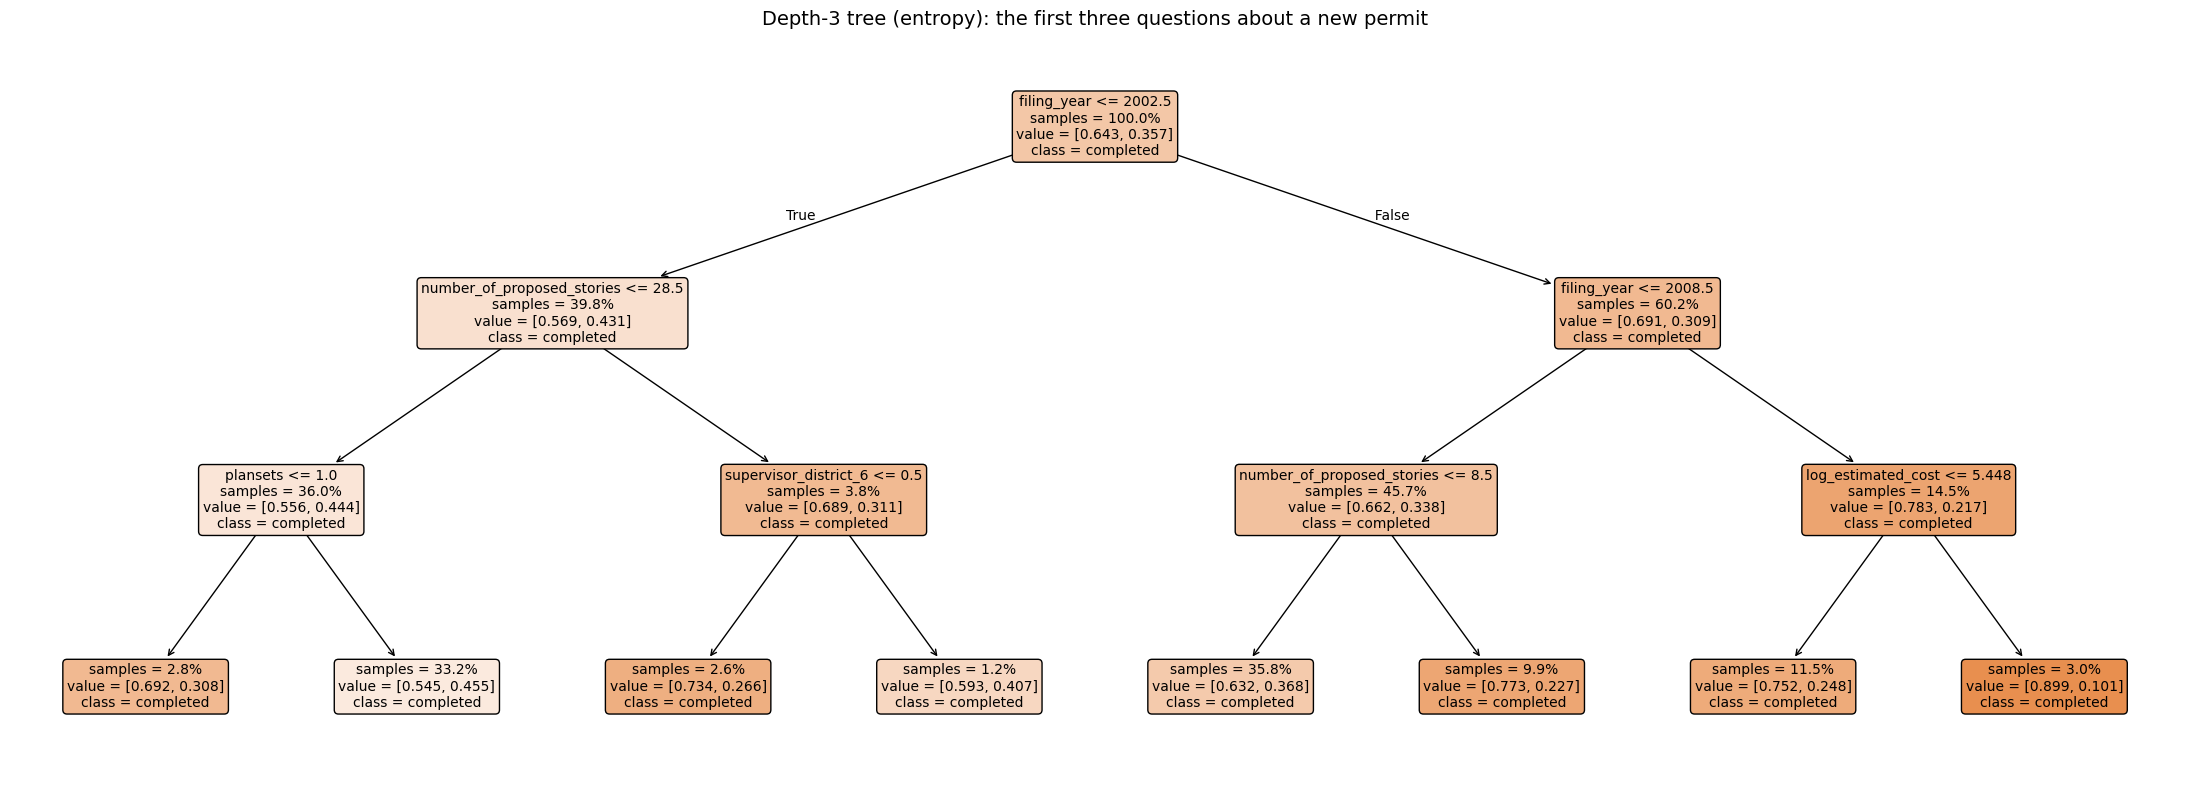

For reference, this depth-3 tree's test AUC is 0.605


In [11]:
# --- Step 5 — draw a depth-3 tree (unscaled numbers so thresholds are readable) ---
def make_unscaled_preprocessor():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))])
    return ColumnTransformer([('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)])

small_tree = Pipeline([('prep', make_unscaled_preprocessor()),
                       ('model', DecisionTreeClassifier(max_depth=3, criterion=best_crit,
                                                        min_samples_leaf=tree_search.best_params_['model__min_samples_leaf'],
                                                        random_state=RANDOM_STATE))]).fit(X_train, y_train)
small_names = [n.replace('num__', '').replace('cat__', '') for n in small_tree.named_steps['prep'].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(small_tree.named_steps['model'], feature_names=small_names, class_names=['completed', 'did not finish'],
          filled=True, proportion=True, impurity=False, rounded=True, fontsize=10, ax=ax)
ax.set_title(f'Depth-3 tree ({best_crit}): the first three questions about a new permit', fontsize=14)
plt.tight_layout(); plt.show()
print(f"For reference, this depth-3 tree's test AUC is {roc_auc_score(y_test, small_tree.predict_proba(X_test)[:, 1]):.3f}")

**Reading the tree:**
- **Every leaf is majority "completed"**, even the riskiest one (45.5% did not finish). At the default 0.5 cutoff a tree like this would flag nobody. The useful information is in the leaf **shares**, which is why everything is compared on AUC and Step 8 chooses a cutoff.
- **Filing year drives the first two levels:** before 2003, 43% did not finish; 2003–2008, 34%; 2009–2013, 22%.
- **Riskiest group:** permits filed before 2003 with **more than one set of plans** (33% of permits): 45.5% did not finish.
- **Safest group:** permits filed 2009–2013 with an **estimated cost above about $280,000** (log10 cost > 5.45): only 10% did not finish.
- **Building size helps:** among 2003–2008 permits, projects proposing more than 8 stories failed 23% of the time, against 37% for smaller ones.

These are associations in historical data, not causes. A tree this shallow is readable but weak (test AUC 0.605, against 0.644 for the tuned depth-15 tree).

## Step 6 — Random forest
A single tree has **high variance**: retrain it on a slightly different sample of permits and the top splits, and every split beneath them, can change. A random forest averages many trees to cancel that noise out:
1. **Bagging:** each tree is trained on a bootstrap sample (permits drawn with replacement) of the training set.
2. **Random feature subsets:** at each split a tree may only consider a random subset of the columns (`max_features`). Without this, every tree would pick the same strong first split and the trees would be too alike to average usefully.
3. The forest's risk score is the **average** of the trees' predicted probabilities.

The trees are grown deep (low bias), and averaging brings the variance down. The cost is interpretability: no single picture of 200 trees exists, so Step 9 uses permutation importance instead.

Tuned hyperparameters:
- **`max_features`**: how many columns each split may look at: `'sqrt'` (≈ 13 of the 166), 0.1 (≈ 17), 0.25 (≈ 42) or 0.4 (≈ 66). Fewer columns = more diverse trees but weaker individual trees.
- **`min_samples_leaf`**: 1, 5 or 20 permits per leaf, as for the single tree.

Forests are slow to fit, so tuning is done in **two rounds** to keep the notebook to a few minutes: first `max_features` (at leaf size 5), then `min_samples_leaf` at the best `max_features`. Each round uses the same grouped 5-fold CV. During tuning each forest has 100 trees, enough to rank settings (checked below); the final forest gets 200. The split criterion is fixed to the tree's winner from Step 4.

⏱ *These two cells take roughly 5–10 minutes on a free Colab machine.*

In [12]:
# --- Step 6 — round 1: max_features ---
def forest_pipe(n_estimators=100, **kw):
    return Pipeline([('prep', make_preprocessor()),
                     ('model', RandomForestClassifier(n_estimators=n_estimators, criterion=best_crit,
                                                      random_state=RANDOM_STATE, n_jobs=-1, **kw))])

t0 = time.time()
rf_round1 = GridSearchCV(forest_pipe(min_samples_leaf=5), {'model__max_features': ['sqrt', 0.1, 0.25, 0.4]},
                         cv=cv, scoring='roc_auc', return_train_score=True)
rf_round1.fit(X_train, y_train, groups=groups_train)
best_mf = rf_round1.best_params_['model__max_features']
print(f'Round 1 in {time.time() - t0:.0f}s · best max_features = {best_mf}')
r1 = pd.DataFrame(rf_round1.cv_results_)
r1 = r1[['param_model__max_features', 'mean_train_score', 'mean_test_score', 'std_test_score']]
r1.columns = ['max_features', 'training AUC', 'CV AUC', 'CV AUC (sd)']
r1.round(4).set_index('max_features')

Round 1 in 109s · best max_features = 0.25


,training AUC,CV AUC,CV AUC (sd)
max_features,,,
sqrt,0.8418,0.6919,0.0051
0.1,0.8686,0.6948,0.0062
0.25,0.9395,0.6993,0.0060
0.4,0.9595,0.6987,0.0056


In [13]:
# --- Step 6 — round 2: min_samples_leaf at the best max_features ---
t0 = time.time()
rf_round2 = GridSearchCV(forest_pipe(max_features=best_mf), {'model__min_samples_leaf': [1, 5, 20]},
                         cv=cv, scoring='roc_auc', return_train_score=True)
rf_round2.fit(X_train, y_train, groups=groups_train)
best_rf_kw = {'max_features': best_mf, 'min_samples_leaf': rf_round2.best_params_['model__min_samples_leaf']}
print(f'Round 2 in {time.time() - t0:.0f}s · best settings: {best_rf_kw} · CV AUC {rf_round2.best_score_:.4f}')
r2 = pd.DataFrame(rf_round2.cv_results_)
r2 = r2[['param_model__min_samples_leaf', 'mean_train_score', 'mean_test_score', 'std_test_score']]
r2.columns = ['min_samples_leaf', 'training AUC', 'CV AUC', 'CV AUC (sd)']
r2.round(4).set_index('min_samples_leaf')

Round 2 in 116s · best settings: {'max_features': 0.25, 'min_samples_leaf': 5} · CV AUC 0.6993


,training AUC,CV AUC,CV AUC (sd)
min_samples_leaf,,,
1,0.9997,0.6955,0.0046
5,0.9395,0.6993,0.0060
20,0.7962,0.6895,0.0044


**Reading the two rounds:**
- **Round 1:** `max_features = 0.25` (≈ 42 columns per split) is best at CV AUC **0.699**. 0.4 scores slightly lower (0.6987 vs. 0.6993), so the peak is inside the range rather than at its edge. `'sqrt'` (0.692) gives trees that are too weak.
- **Round 2:** leaves of **5** permits are best. Leaves of 1 (0.696) let each tree memorise its sample (training AUC 0.9997), and leaves of 20 (0.690) smooth away real patterns.
- **Why the high training AUC is fine here:** a forest always scores high on its own training permits, because each tree saw most of them. What matters is the CV column: **≈ 0.70, against 0.652 for the best single tree**. Averaging 100 de-correlated trees bought about +0.05 AUC.

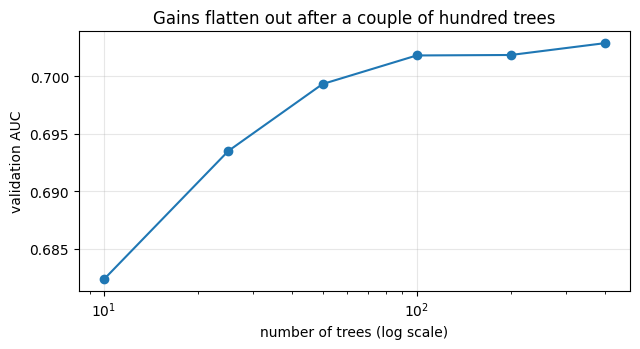

trees,10,25,50,100,200,400
validation AUC,0.6823,0.6935,0.6993,0.7018,0.7018,0.7029


In [14]:
# --- Step 6 — does adding trees help? (one grouped validation fold inside the training set) ---
fit_idx, val_idx = next(cv.split(X_train, y_train, groups_train))
rf_prep = make_preprocessor().fit(X_train.iloc[fit_idx])
Xf, Xv = rf_prep.transform(X_train.iloc[fit_idx]), rf_prep.transform(X_train.iloc[val_idx])
forest = RandomForestClassifier(n_estimators=10, criterion=best_crit, warm_start=True,
                                random_state=RANDOM_STATE, n_jobs=-1, **best_rf_kw)
n_trees, val_auc = [10, 25, 50, 100, 200, 400], []
for n in n_trees:
    forest.set_params(n_estimators=n).fit(Xf, y_train.iloc[fit_idx])     # warm_start: adds trees
    val_auc.append(roc_auc_score(y_train.iloc[val_idx], forest.predict_proba(Xv)[:, 1]))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(n_trees, val_auc, marker='o'); ax.set_xscale('log')
ax.set_xlabel('number of trees (log scale)'); ax.set_ylabel('validation AUC'); ax.grid(alpha=0.3)
ax.set_title('Gains flatten out after a couple of hundred trees')
plt.tight_layout(); plt.show()
pd.DataFrame({'trees': n_trees, 'validation AUC': np.round(val_auc, 4)}).set_index('trees').T

**Reading the curve:** validation AUC climbs quickly up to 50–100 trees (0.682 → 0.702), then flattens: 200 trees give the same 0.702 and 400 only 0.703. So 100 trees were enough to *rank* settings during tuning, and the final forest uses 200 as a safe margin. More trees never make a forest overfit; they only cost time.

In [15]:
# --- Step 6 — the final forest: tuned settings, 200 trees, fitted on all training permits ---
best_rf = forest_pipe(n_estimators=200, **best_rf_kw)
t0 = time.time(); best_rf.fit(X_train, y_train); rf_time = time.time() - t0
print(f'Final forest: {best_rf_kw}, 200 trees · fitted in {rf_time:.0f}s')
print(f'Its CV AUC from tuning (100 trees): {rf_round2.best_score_:.4f}')

Final forest: {'max_features': 0.25, 'min_samples_leaf': 5}, 200 trees · fitted in 18s
Its CV AUC from tuning (100 trees): 0.6993


## Step 7 — Test-set results: every model, once
Now, and only now, each tuned model is scored on the held-out test permits. Logistic regression is refitted here with the best settings from `02_logistic.ipynb`, so all four rows use exactly the same test permits.

Metrics:
- **ROC AUC:** the chance that a randomly chosen failed permit gets a higher risk score than a randomly chosen completed one. 0.5 = coin flip, 1 = perfect. This is the main yardstick because it does not depend on a cutoff.
- **Accuracy / error rate:** share of permits classified right / wrong at cutoff 0.5. Misleading on its own: "always completed" already gets ~63%.
- **Recall:** share of failing permits that get flagged. **Precision:** share of flagged permits that really fail. **F1:** their harmonic mean.

In [16]:
# --- Step 7 — refit logistic regression with the settings from 02_logistic.ipynb ---
LOGISTIC_BEST = {'C': 0.1, 'class_weight': 'balanced'}   # printed at the end of 02_logistic.ipynb
logit = Pipeline([('prep', make_preprocessor()),
                  ('model', LogisticRegression(max_iter=3000, **LOGISTIC_BEST))])
t0 = time.time(); logit.fit(X_train, y_train); logit_time = time.time() - t0
logit_cv = cross_validate(Pipeline([('prep', make_preprocessor()),
                                    ('model', LogisticRegression(max_iter=3000, **LOGISTIC_BEST))]),
                          X_train, y_train, groups=groups_train, cv=cv, scoring='roc_auc', n_jobs=-1)['test_score']

best_tree = tree_search.best_estimator_
models = {'Logistic regression': logit, 'Decision tree (tuned)': best_tree, 'Random forest (tuned)': best_rf}
cv_auc = {'Logistic regression': logit_cv.mean(), 'Decision tree (tuned)': tree_search.best_score_,
          'Random forest (tuned)': rf_round2.best_score_}

def scores(name, y_true, prob, pred, cv_value=np.nan):
    return {'model': name, 'CV AUC (train)': cv_value, 'test ROC AUC': roc_auc_score(y_true, prob),
            'accuracy': accuracy_score(y_true, pred), 'error rate': 1 - accuracy_score(y_true, pred),
            'recall': recall_score(y_true, pred, zero_division=0),
            'precision': precision_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0), 'share flagged': pred.mean()}

rows, probs = [], {}
for name, strategy in [('Baseline: always "completed"', 'most_frequent'), ('Baseline: random guess', 'stratified')]:
    d = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append(scores(name, y_test, d.predict_proba(X_test)[:, 1], d.predict(X_test)))
for name, m in models.items():
    probs[name] = m.predict_proba(X_test)[:, 1]
    rows.append(scores(name, y_test, probs[name], (probs[name] >= 0.5).astype(int), cv_auc[name]))
results = pd.DataFrame(rows).set_index('model').round(3)
results

,CV AUC (train),test ROC AUC,accuracy,error rate,recall,precision,F1,share flagged
model,,,,,,,,
"Baseline: always ""completed""",NaN,0.500,0.633,0.367,0.000,0.000,0.000,0.000
Baseline: random guess,NaN,0.498,0.538,0.462,0.349,0.365,0.357,0.351
Logistic regression,0.638,0.633,0.585,0.415,0.605,0.452,0.517,0.493
Decision tree (tuned),0.652,0.644,0.639,0.361,0.248,0.519,0.336,0.176
Random forest (tuned),0.699,0.698,0.669,0.331,0.335,0.588,0.427,0.209


**Reading the table:**
- **Ranking ability (AUC):** random forest **0.698** > decision tree 0.644 > logistic regression 0.633 > baselines 0.50. All three real models beat both baselines.
- **CV and test agree** for every model (forest 0.699 CV vs. 0.698 test, tree 0.652 vs. 0.644, logistic 0.638 vs. 0.633). The test set confirms the tuning instead of contradicting it, so there are no signs of overfitting to the validation folds.
- **Error rate:** the forest's 33.1% beats "always completed" (36.7%) by only 3.6 points. That is why accuracy alone is a poor yardstick when one class dominates.
- **Recall and precision at 0.5 are not a fair comparison.** Logistic regression was tuned with `class_weight='balanced'`, which pushes its probabilities up, so it flags 49% of permits (high recall, low precision). The tree and the forest are unweighted and flag about 20%. Compare models on AUC, and choose the cutoff deliberately (Step 8). Even so, of the permits the forest flags at 0.5, **59% really fail**, against a 37% base rate.

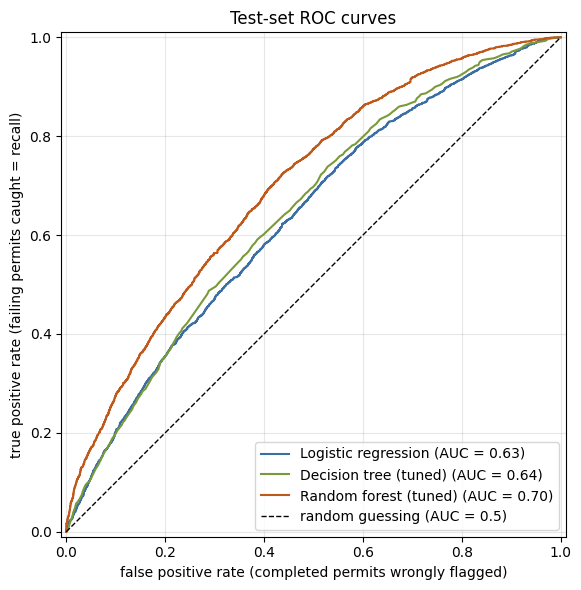

In [17]:
# --- Step 7 — ROC curves on the test set ---
fig, ax = plt.subplots(figsize=(6.5, 6))
for (name, pr), color in zip(probs.items(), ['#3b6ea5', '#7a9a3a', '#c0581a']):
    RocCurveDisplay.from_predictions(y_test, pr, name=name, ax=ax, color=color)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='random guessing (AUC = 0.5)')
ax.set_xlabel('false positive rate (completed permits wrongly flagged)')
ax.set_ylabel('true positive rate (failing permits caught = recall)')
ax.set_title('Test-set ROC curves'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Is the gap real or luck?** One test set gives one AUC per model. Resampling the test permits 1,000 times (bootstrap) shows how much each AUC, and each *difference* between models, would wobble on another sample of permits of the same size.

In [18]:
# --- Step 7 — bootstrap 95% intervals for test AUC and for the differences ---
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
boot = {name: [] for name in probs}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    for name, pr in probs.items():
        boot[name].append(roc_auc_score(yt[i], pr[i]))
boot = pd.DataFrame(boot)
boot['Forest − logistic'] = boot['Random forest (tuned)'] - boot['Logistic regression']
boot['Forest − tree'] = boot['Random forest (tuned)'] - boot['Decision tree (tuned)']
boot['Tree − logistic'] = boot['Decision tree (tuned)'] - boot['Logistic regression']
boot.quantile([0.025, 0.5, 0.975]).T.round(3).set_axis(['2.5%', 'median', '97.5%'], axis=1)

,2.5%,median,97.5%
Logistic regression,0.623,0.633,0.643
Decision tree (tuned),0.634,0.644,0.654
Random forest (tuned),0.688,0.697,0.706
Forest − logistic,0.056,0.064,0.073
Forest − tree,0.045,0.053,0.061
Tree − logistic,0.002,0.011,0.020


**Reading the intervals:**
- **Forest vs. logistic:** +0.064 AUC, 95% interval 0.056 to 0.073.
- **Forest vs. tree:** +0.053, interval 0.045 to 0.061.

Neither interval comes close to 0, so the **forest's lead is real**, not luck of the test sample. The tree's edge over logistic regression (+0.011, interval 0.002 to 0.020) is barely above zero: those two are close.

*Caveat:* the bootstrap resamples individual permits, not project batches, so these intervals are a little narrower than they should be. With gaps this large, the conclusion does not change.

## Step 8 — Choosing the flagging cutoff
A cutoff of 0.5 is arbitrary. The right cutoff depends on what each mistake costs the city:
- **Missed failure (false negative):** a project that will be abandoned gets no attention. Planned homes are lost, and the site may sit half-built.
- **False alarm (false positive):** staff spend time on outreach to a project that would have finished anyway.

A missed failure is plausibly several times worse than a false alarm. The ratio is a **policy assumption, not a statistical fact**. We use 3 : 1 as the working value and show 1, 2, 3 and 5 so the reader can see how much it matters.

To avoid tuning on the test set, the cutoff is chosen on **cross-validated predictions for the training permits** (each permit scored by a model that never saw it), then applied once to the test set. This is done for the model with the best CV AUC.

Model used for flagging: Random forest (tuned)


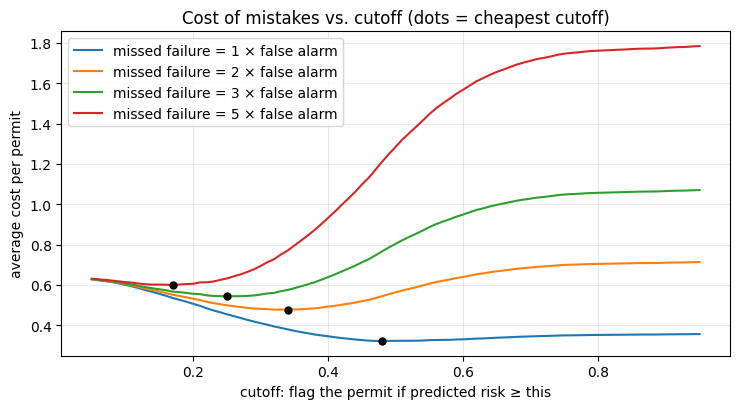

,cutoff (from training CV),test recall,test precision,share of permits flagged,test accuracy
cost ratio (miss : false alarm),,,,,
1 : 1,0.48,0.383,0.573,0.246,0.668
2 : 1,0.34,0.724,0.490,0.543,0.622
3 : 1,0.25,0.876,0.446,0.723,0.554
5 : 1,0.17,0.960,0.409,0.862,0.476


In [19]:
# --- Step 8 — pick the cutoff on out-of-fold training predictions ---
chosen = max(cv_auc, key=cv_auc.get)
print('Model used for flagging:', chosen)
oof = cross_val_predict(models[chosen], X_train, y_train, groups=groups_train, cv=cv, method='predict_proba')[:, 1]

cutoffs = np.round(np.arange(0.05, 0.96, 0.01), 2)
def expected_cost(y_true, prob, cut, fn_cost, fp_cost=1):
    pred = prob >= cut
    fn = ((y_true == 1) & ~pred).sum(); fp = ((y_true == 0) & pred).sum()
    return (fn_cost * fn + fp_cost * fp) / len(y_true)

rows = []
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for ratio in [1, 2, 3, 5]:
    cost = [expected_cost(y_train.to_numpy(), oof, c, ratio) for c in cutoffs]
    cut = cutoffs[int(np.argmin(cost))]
    ax.plot(cutoffs, cost, label=f'missed failure = {ratio} × false alarm')
    ax.plot(cut, min(cost), 'ko', ms=5)
    pred = (probs[chosen] >= cut).astype(int)                      # applied once to the test set
    rows.append({'cost ratio (miss : false alarm)': f'{ratio} : 1', 'cutoff (from training CV)': cut,
                 'test recall': recall_score(y_test, pred), 'test precision': precision_score(y_test, pred),
                 'share of permits flagged': pred.mean(), 'test accuracy': accuracy_score(y_test, pred)})
ax.set_xlabel('cutoff: flag the permit if predicted risk ≥ this'); ax.set_ylabel('average cost per permit')
ax.set_title('Cost of mistakes vs. cutoff (dots = cheapest cutoff)'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
cutoff_table = pd.DataFrame(rows).set_index('cost ratio (miss : false alarm)').round(3)
cutoff_table

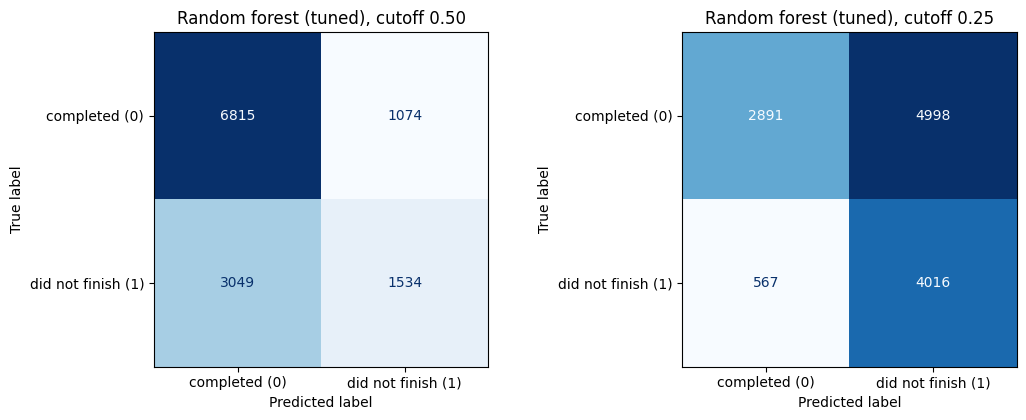

In [20]:
# --- Step 8 — confusion matrices: default 0.5 vs. the 3 : 1 cost cutoff ---
cut3 = cutoff_table.loc['3 : 1', 'cutoff (from training CV)']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, cut in zip(axes, [0.5, cut3]):
    ConfusionMatrixDisplay.from_predictions(y_test, (probs[chosen] >= cut).astype(int),
                                            display_labels=['completed (0)', 'did not finish (1)'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{chosen}, cutoff {cut:.2f}')
plt.tight_layout(); plt.show()

**A second way to set the cutoff: staff capacity.** If the department can only follow up on a fixed share of new permits, the question becomes: if we review the riskiest 10%, 20% or 30% of permits, how many of the failures do we reach?

In [21]:
# --- Step 8 — flag the riskiest k% of test permits ---
rows = []
for k in [0.05, 0.10, 0.20, 0.30, 0.50]:
    cut = np.quantile(probs[chosen], 1 - k)
    pred = (probs[chosen] >= cut).astype(int)
    rows.append({'review the riskiest': f'{k:.0%}', 'failures caught (recall)': recall_score(y_test, pred),
                 'flagged that really fail (precision)': precision_score(y_test, pred),
                 'lift over random review': precision_score(y_test, pred) / y_test.mean()})
pd.DataFrame(rows).set_index('review the riskiest').round(3)

,failures caught (recall),flagged that really fail (precision),lift over random review
review the riskiest,,,
5%,0.101,0.740,2.015
10%,0.177,0.650,1.768
20%,0.321,0.590,1.606
30%,0.451,0.552,1.502
50%,0.676,0.497,1.353


**Reading the cost analysis (random forest):**
- With equal costs (1 : 1) the best cutoff is 0.48, close to the default.
- As a missed failure gets more expensive, the cutoff drops and more permits get flagged. At **2 : 1**, the model flags 54% of permits and catches 72% of the failures. At **3 : 1**, it flags 72% and catches 88%, with 45% of flagged permits really failing.
- **Honest read:** at 3 : 1 the model flags almost three quarters of all permits. That is not a targeted list. With an AUC of 0.70 the signal is real but modest, so no cutoff gets high recall *and* a short list at the same time.

**Reading the capacity table:** this is the more practical framing for the city. If staff review the **riskiest 10%** of new permits, 65% of those permits really fail (1.8× the 37% base rate), and they reach 18% of all failures. At the riskiest 5% the hit rate is 74%, twice the base rate. The model works best as a **priority list for outreach** (extensions, fee deferrals), not as a gate that blocks permits.

## Step 9 — What drives the forest?
A forest has no coefficients. **Permutation importance** asks: if we shuffle one column of the test set (breaking its link to the outcome) and keep everything else, how much does test AUC drop? A big drop means the forest relies on that feature. It works on the original 23 features rather than the 166 one-hot columns, so a categorical variable such as *neighbourhood* is judged as a whole.

(The forest also reports its own "impurity-based" importance, the total Gini or entropy decrease per column, but that is known to favour columns with many distinct values such as cost, so permutation importance is the safer read.)

computed in 12s


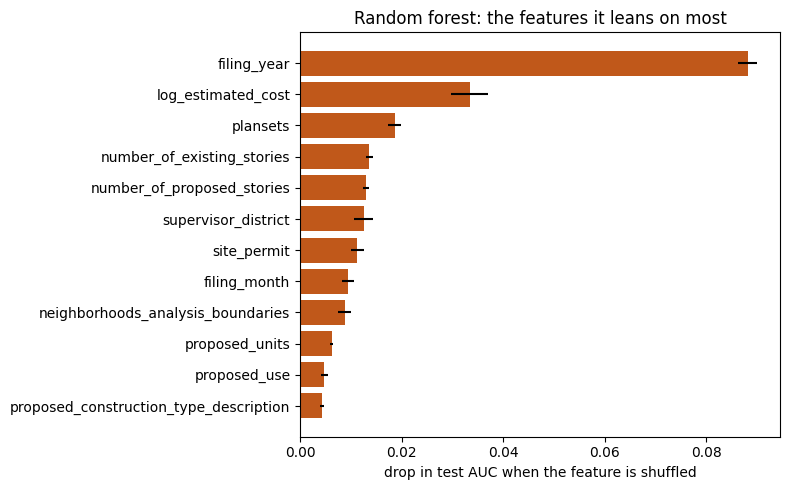

,feature,AUC drop (mean),AUC drop (sd)
0,filing_year,0.0882,0.0019
1,log_estimated_cost,0.0334,0.0036
2,plansets,0.0186,0.0012
3,number_of_existing_stories,0.0136,0.0006
4,number_of_proposed_stories,0.0130,0.0006
5,supervisor_district,0.0126,0.0019
6,site_permit,0.0113,0.0014
7,filing_month,0.0094,0.0011
8,neighborhoods_analysis_boundaries,0.0088,0.0013
9,proposed_units,0.0062,0.0003


In [22]:
# --- Step 9 — permutation importance on the test set (drop in AUC when a feature is shuffled) ---
t0 = time.time()
perm = permutation_importance(best_rf, X_test, y_test, scoring='roc_auc', n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({'feature': X_test.columns, 'AUC drop (mean)': perm.importances_mean,
                     'AUC drop (sd)': perm.importances_std})
       .sort_values('AUC drop (mean)', ascending=False).reset_index(drop=True))
print(f'computed in {time.time() - t0:.0f}s')
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top['feature'], top['AUC drop (mean)'], xerr=top['AUC drop (sd)'], color='#c0581a')
ax.set_xlabel('drop in test AUC when the feature is shuffled')
ax.set_title('Random forest: the features it leans on most')
plt.tight_layout(); plt.show()
imp.round(4)

**Reading the importances:**
- **`filing_year` dominates** (AUC drop 0.088), more than the next two features combined.
- Next comes the **size and cost of the project**: `log_estimated_cost` 0.033, `plansets` 0.019, existing and proposed stories ≈ 0.013 each.
- Then **location** (`supervisor_district`, `neighborhoods_analysis_boundaries`) and whether it is a `site_permit`.
- **Little added value** from permit type, use changes and unit changes once those are known.

Correlated features *share* credit. Shuffling `number_of_existing_stories` leaves `number_of_proposed_stories` (nearly the same information) intact, and the same goes for district and neighbourhood. So those features each look less important than the information they carry together.

In [23]:
# --- Step 9 — how much of the signal is just "when was it filed"? Refit without filing_year/filing_month ---
NO_DATE = [c for c in NUMERIC if c not in ('filing_year', 'filing_month')]
def prep_without_dates():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))])
    return ColumnTransformer([('num', numeric, NO_DATE), ('cat', categorical, CATEGORICAL)])

rows = []
for name, model in [('Logistic regression', LogisticRegression(max_iter=3000, **LOGISTIC_BEST)),
                    ('Random forest (tuned)', RandomForestClassifier(n_estimators=200, criterion=best_crit,
                                                                     random_state=RANDOM_STATE, n_jobs=-1, **best_rf_kw))]:
    m = Pipeline([('prep', prep_without_dates()), ('model', model)]).fit(X_train, y_train)
    rows.append({'model': name, 'test AUC with dates': roc_auc_score(y_test, probs[name]),
                 'test AUC without filing year/month': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
pd.DataFrame(rows).set_index('model').round(3)

,test AUC with dates,test AUC without filing year/month
model,,
Logistic regression,0.633,0.606
Random forest (tuned),0.698,0.655


**Reading the check:** without the filing date, the forest's test AUC falls from **0.698 to 0.655**, and logistic regression's from 0.633 to 0.606. Two conclusions:
1. **The forest's advantage is not just the date.** It still beats logistic regression by about 0.05 on project details alone.
2. **A large share of the signal is "when it was filed".** That is a problem for real use. The model learned that older permits failed more often, but every permit filed today has a year beyond 2013, and a tree cannot extrapolate: it treats 2025 like 2013, the lowest-risk years it has seen. **0.655 is the more honest estimate** of what application details alone can do for a new permit, and the report should quote both numbers.

## Step 10 — Comparison and conclusions

In [24]:
# --- Step 10 — summary table for the report ---
fit_time = {'Logistic regression': logit_time, 'Decision tree (tuned)': tree_time, 'Random forest (tuned)': rf_time}
summary = results.loc[list(models), ['CV AUC (train)', 'test ROC AUC', 'error rate', 'recall', 'precision']].copy()
summary['seconds to fit'] = pd.Series(fit_time).round(1)
summary['interpretable?'] = ['yes: one odds ratio per feature', 'yes: a flowchart of rules',
                             'partly: importance only']
summary

,CV AUC (train),test ROC AUC,error rate,recall,precision,seconds to fit,interpretable?
model,,,,,,,
Logistic regression,0.638,0.633,0.415,0.605,0.452,0.6,yes: one odds ratio per feature
Decision tree (tuned),0.652,0.644,0.361,0.248,0.519,0.6,yes: a flowchart of rules
Random forest (tuned),0.699,0.698,0.331,0.335,0.588,18.2,partly: importance only


### What we found
1. **The random forest is the best predictor**: test AUC **0.698**, against 0.644 for the tuned tree and 0.633 for logistic regression. It also has the lowest error rate (33.1%). The bootstrap shows the lead is real.
2. **Why it wins:** the patterns are non-linear and interact. In the drawn tree, cost matters differently depending on the filing year, and the number of stories matters in thresholds, not as a straight line. Logistic regression cannot capture this without hand-built interaction terms. A single tree can, but noisily (its top splits change with the sample). The forest keeps the flexibility and averages the noise away.
3. **Gini vs. entropy hardly matters.** Their best trees differ by 0.002 AUC, within noise. Misclassification error is not usable for growing trees: on our data it could not even score the first split.
4. **Tuning mattered more than the criterion.** For the tree, going from fully grown to tuned (depth 15, leaves ≥ 200) took CV AUC from 0.585 to 0.652. For the forest, the column subset (`max_features`) and leaf size together moved it about 0.01.

### Answer to the question
**Partly.** Details on the application rank permits clearly better than chance (AUC ≈ 0.70, or ≈ 0.66 without the filing date), but far from perfectly. The riskiest 10% of permits fail 65% of the time, against 37% on average. That is good enough to **prioritise outreach**, and not good enough to deny or delay a permit on the model's say-so.

### Trade-offs

| | Logistic regression | Decision tree | Random forest |
|---|---|---|---|
| Ranking (test AUC) | 0.633 | 0.644 | **0.698** |
| Explaining a flag to an applicant | odds ratio per feature | a short list of if-then rules | only overall importance |
| Fit time | < 1 s | < 1 s | ≈ 20 s (still trivial for a city) |

A sensible split for the department: the **forest produces the ranked list**, and the **tree or logistic regression explains it** to staff and applicants.

### Limitations to state in the report
- **Time drift:** much of the signal is the filing year, and no permit filed after 2013 was used (their outcomes were not final yet). Retrain on recent resolved permits before any real use, and quote the AUC without dates.
- **The cost ratio in Step 8 is an assumption** for DBI to set, not something the data can tell us.
- **Bootstrap intervals** resample permits rather than project batches, so they are slightly too narrow.
- **Associations, not causes:** "more plan sets → more risk" does not mean that asking for fewer plans would help.